In [1]:
# TAREA 1
import matplotlib.pyplot as plt

lugares = {
    "La UNSAAC": (-13.521848, -71.959017),
    "Casa en Cusco": (-13.548218, -71.927168),
    "Casa de Origen": (-13.669821, -71.315941),
    "Casa Cualquiera": (-13.534574, -71.926167),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

La UNSAAC: lat=-13.521848, lon=-71.959017
Casa en Cusco: lat=-13.548218, lon=-71.927168
Casa de Origen: lat=-13.669821, lon=-71.315941
Casa Cualquiera: lat=-13.534574, lon=-71.926167


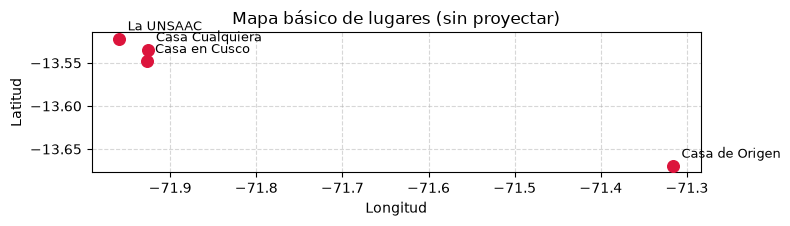

In [2]:
lats = [coord[0] for coord in lugares.values()]
lons = [coord[1] for coord in lugares.values()]
nombres = list(lugares.keys())

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(lons, lats, c="crimson", s=70, zorder=3)

for nombre, lat, lon in zip(nombres, lats, lons):
    ax.annotate(
        nombre,
        (lon, lat),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=9,
    )

ax.set_title("Mapa básico de lugares (sin proyectar)")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("mapa_basico.png", dpi=300)
plt.show()

In [3]:
#TAREA 2
import math
from itertools import combinations

def distancia_haversine(lat1, lon1, lat2, lon2, radio_km=6371.0):
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)

    a = (
        math.sin(dphi / 2) ** 2
        + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    )
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return radio_km * c

In [5]:
# Distancias desde el primer lugar ("La UNSAAC")
primer_nombre, (lat0, lon0) = next(iter(lugares.items()))
print(f"\nDistancias desde '{primer_nombre}':")
for nombre, (lat, lon) in lugares.items():
    if nombre != primer_nombre:
        d = distancia_haversine(lat0, lon0, lat, lon)
        print(f"  -> {nombre}: {d:.2f} km")


Distancias desde 'La UNSAAC':
  -> Casa en Cusco: 4.52 km
  -> Casa de Origen: 71.42 km
  -> Casa Cualquiera: 3.82 km


In [6]:
# Todas las combinaciones para identificar el par más cercano y el más lejano
pares_distancias = []
for (n1, (lat1, lon1)), (n2, (lat2, lon2)) in combinations(lugares.items(), 2):
    d = distancia_haversine(lat1, lon1, lat2, lon2)
    pares_distancias.append((d, n1, n2))

mas_cercano = min(pares_distancias, key=lambda x: x[0])
mas_lejano = max(pares_distancias, key=lambda x: x[0])

print(f"\nPar más cercano: {mas_cercano[1]} y {mas_cercano[2]} ({mas_cercano[0]:.2f} km)")
print(f"Par más lejano:  {mas_lejano[1]} y {mas_lejano[2]} ({mas_lejano[0]:.2f} km)")


Par más cercano: Casa en Cusco y Casa Cualquiera (1.52 km)
Par más lejano:  La UNSAAC y Casa de Origen (71.42 km)


In [9]:
#TAREA 3
import json

features = []
for nombre, (lat, lon) in lugares.items():
    feature = {
        "type": "Feature",
        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat],
        },
        "properties": {
            "nombre": nombre,
        },
    }
    features.append(feature)

geojson_mio = {
    "type": "FeatureCollection",
    "features": features,
}

with open("mis_lugares.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson_mio, f, ensure_ascii=False, indent=2)

In [8]:
# Reabrir y verificar
with open("mis_lugares.geojson", "r", encoding="utf-8") as f:
    geojson_cargado = json.load(f)

num_features = len(geojson_cargado["features"])
primer_coords = geojson_cargado["features"][0]["geometry"]["coordinates"]
esperado_coords = [lugares["La UNSAAC"][1], lugares["La UNSAAC"][0]]

print("Número de features:", num_features)
print("Coordenadas del primer lugar [lon, lat]:", primer_coords)
print("Coincide con lo esperado:", primer_coords == esperado_coords)

Número de features: 4
Coordenadas del primer lugar [lon, lat]: [-71.959017, -13.521848]
Coincide con lo esperado: True
